# LSTM Temperature Prediction — Magnet Power Supply
### Based on: *Long Short-Term Memory Networks for Anomaly Detection in Magnet Power Supplies of Particle Accelerators* (arXiv:2405.18321v1)

**Scope of this notebook**
- This notebook implements **only** the LSTM *predictor* described in the paper's methodology.
- It predicts component temperature (`MeasuredTemperature_C`, falling back to `TrueTemperature_C`) from historical `Current_A` values.
- **No anomaly detection and no fault injection are performed here.** Those steps belong to a follow-up notebook that will consume the trained model produced here.
- The dataset (`magnet_power_supply_dataset.csv`) is assumed to already exist — this notebook does **not** generate synthetic data.

**Pipeline**
1. Environment setup
2. Load & inspect data
3. Preprocessing (sort, scale, train/test split — no shuffling, since this is a time series)
4. Sliding-window sequence creation (window = 50 → predict t+1)
5. LSTM model definition (Keras)
6. Training with EarlyStopping
7. Model saving (`lstm_temperature_model.keras`)
8. Evaluation (MAE, RMSE, MSE, R²)
9. Publication-quality visualizations
10. Export predictions (`prediction_results.csv`)


## 1. Environment Setup

Installs/imports all required libraries. Compatible with Google Colab's default runtime (TensorFlow 2.x preinstalled).
If running locally, uncomment the `pip install` line.


In [1]:
# Uncomment the line below if any package is missing (not usually needed on Colab)
# !pip install tensorflow scikit-learn pandas numpy matplotlib --quiet

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Reproducibility: fix random seeds for NumPy and TensorFlow
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load Dataset

The dataset is expected to be named `magnet_power_supply_dataset.csv`.

- If you are running this in **Google Colab** and the file is not already present in the runtime,
  the cell below will open a file-upload widget so you can upload it directly from your computer.
- If the file already exists (e.g. you mounted Google Drive or uploaded it beforehand), the upload
  step is skipped automatically.


In [2]:
DATA_PATH = "magnet_power_supply_dataset.csv"

# If the file isn't already present, try the Colab upload widget.
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files  # only available inside Colab
        print("Dataset not found locally. Please upload 'magnet_power_supply_dataset.csv'.")
        uploaded = files.upload()
        # Use the first uploaded file's name as the dataset path
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"Could not find '{DATA_PATH}'. Place the dataset in the working directory "
            "or update DATA_PATH to point to its location."
        )

print(f"Using dataset file: {DATA_PATH}")


Dataset not found locally. Please upload 'magnet_power_supply_dataset.csv'.


Saving magnet_power_supply_dataset (1).csv to magnet_power_supply_dataset (1).csv
Using dataset file: magnet_power_supply_dataset (1).csv


## 3. Load & Inspect Data

Load the CSV into a Pandas DataFrame and perform basic sanity checks:
- Preview the data
- Check column names
- Check for missing values
- Determine which temperature column to use (`MeasuredTemperature_C` preferred, `TrueTemperature_C` as fallback)


In [3]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:", list(df.columns))
print("\nFirst 5 rows:")
display(df.head())

# Determine the target temperature column, per task instructions
if "MeasuredTemperature_C" in df.columns and df["MeasuredTemperature_C"].notna().any():
    TARGET_COL = "MeasuredTemperature_C"
elif "TrueTemperature_C" in df.columns:
    TARGET_COL = "TrueTemperature_C"
else:
    raise ValueError("Neither 'MeasuredTemperature_C' nor 'TrueTemperature_C' found in dataset.")

INPUT_COL = "Current_A"
TIME_COL = "Time_s"

print(f"\nUsing input feature : '{INPUT_COL}'")
print(f"Using target column  : '{TARGET_COL}'")

# Confirm required columns exist
for col in [INPUT_COL, TARGET_COL, TIME_COL]:
    if col not in df.columns:
        raise ValueError(f"Required column '{col}' not found in dataset.")


Dataset shape: (50000, 10)

Column names: ['Sample', 'Time_s', 'Current_A', 'AmbientTemperature_C', 'ElectricalResistance_Ohm', 'Power_W', 'TrueTemperature_C', 'MeasuredTemperature_C', 'FaultLabel', 'FaultType']

First 5 rows:


,Sample,Time_s,Current_A,AmbientTemperature_C,ElectricalResistance_Ohm,Power_W,TrueTemperature_C,MeasuredTemperature_C,FaultLabel,FaultType
0,0,0.0,0.018349,24.962469,0.800000,0.000067,24.999935,25.0,0,NaN
1,1,1.0,0.039896,25.065963,0.800000,0.000678,25.000050,25.0,0,NaN
2,2,2.0,0.061317,25.062598,0.800000,0.002049,25.000159,25.0,0,NaN
3,3,3.0,0.085423,24.920191,0.800001,0.004307,25.000023,25.0,0,NaN
4,4,4.0,0.102672,24.927175,0.800000,0.007076,24.999900,25.0,0,NaN



Using input feature : 'Current_A'
Using target column  : 'MeasuredTemperature_C'


In [4]:
# Check for missing values in the relevant columns
missing_report = df[[TIME_COL, INPUT_COL, TARGET_COL]].isna().sum()
print("Missing value counts:")
print(missing_report)

total_missing = missing_report.sum()
if total_missing > 0:
    print(f"\nFound {total_missing} missing values — dropping affected rows.")
    df = df.dropna(subset=[TIME_COL, INPUT_COL, TARGET_COL]).reset_index(drop=True)
else:
    print("\nNo missing values found in the required columns.")


Missing value counts:
Time_s                   0
Current_A                0
MeasuredTemperature_C    0
dtype: int64

No missing values found in the required columns.


## 4. Preprocessing

Steps:
1. Sort the dataset chronologically by `Time_s` (essential for a time-series model).
2. Extract the input (`Current_A`) and target (temperature) as separate arrays.
3. Normalize both input and target to the [0, 1] range using **separate** `MinMaxScaler` instances
   (fit only on the training portion to avoid data leakage).
4. Split into 80% training / 20% testing **without shuffling**, preserving temporal order.


In [5]:
# 1. Sort chronologically by Time_s
df = df.sort_values(by=TIME_COL).reset_index(drop=True)

# 2. Extract relevant arrays
current_values = df[INPUT_COL].values.reshape(-1, 1)      # shape: (N, 1)
temperature_values = df[TARGET_COL].values.reshape(-1, 1) # shape: (N, 1)
time_values = df[TIME_COL].values                         # shape: (N,)

print("Total number of samples (raw, before windowing):", len(df))


Total number of samples (raw, before windowing): 50000


In [6]:
# 3 & 4. Chronological train/test split (80/20, no shuffling) performed BEFORE scaling
# to prevent test-set information from leaking into the scaler fit.
split_idx = int(len(df) * 0.8)

train_current_raw = current_values[:split_idx]
test_current_raw  = current_values[split_idx:]

train_temp_raw = temperature_values[:split_idx]
test_temp_raw  = temperature_values[split_idx:]

train_time = time_values[:split_idx]
test_time  = time_values[split_idx:]

print(f"Training rows: {len(train_current_raw)}  |  Testing rows: {len(test_current_raw)}")

# Fit scalers ONLY on the training data, then transform both train and test
current_scaler = MinMaxScaler(feature_range=(0, 1))
temp_scaler = MinMaxScaler(feature_range=(0, 1))

train_current_scaled = current_scaler.fit_transform(train_current_raw)
test_current_scaled  = current_scaler.transform(test_current_raw)

train_temp_scaled = temp_scaler.fit_transform(train_temp_raw)
test_temp_scaled  = temp_scaler.transform(test_temp_raw)

print("Scaling complete.")
print("Train current range (scaled):", train_current_scaled.min(), "-", train_current_scaled.max())
print("Test  current range (scaled):", test_current_scaled.min(), "-", test_current_scaled.max())


Training rows: 40000  |  Testing rows: 10000
Scaling complete.
Train current range (scaled): 0.0 - 1.0
Test  current range (scaled): 0.031068193087129322 - 0.9142991066172613


## 5. Sliding Window Sequence Creation

For each time step `t`, build an input sequence consisting of the current values from
`t-49` to `t` (a window of 50 samples), and set the prediction target to the temperature
at `t+1`.

Resulting shapes:
- `X`: `(samples, 50, 1)`
- `y`: `(samples, 1)`

This is applied **separately** to the (already scaled) training and testing arrays so that
no window straddles the train/test boundary.


In [7]:
WINDOW_SIZE = 50

def create_sequences(current_arr, temp_arr, window_size):
    """
    Build sliding-window sequences.

    current_arr : scaled current values, shape (N, 1)
    temp_arr    : scaled temperature values, shape (N, 1)
    window_size : number of historical current samples per window (t-49 ... t)

    Returns:
        X : shape (samples, window_size, 1) -- current history
        y : shape (samples, 1)              -- temperature at t+1
    """
    X, y = [], []
    # We need window_size points for the input (t-49..t) and one more point (t+1) for the target
    for i in range(window_size - 1, len(current_arr) - 1):
        window_start = i - window_size + 1
        window_end = i + 1  # exclusive
        X.append(current_arr[window_start:window_end, 0])  # Current_A history: t-49 .. t
        y.append(temp_arr[i + 1, 0])                        # Temperature target: t+1
    X = np.array(X).reshape(-1, window_size, 1)
    y = np.array(y).reshape(-1, 1)
    return X, y

X_train, y_train = create_sequences(train_current_scaled, train_temp_scaled, WINDOW_SIZE)
X_test, y_test   = create_sequences(test_current_scaled, test_temp_scaled, WINDOW_SIZE)

# Keep the Time_s values aligned with each test target (t+1) for later export
test_time_targets = test_time[WINDOW_SIZE:len(test_current_scaled)]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)
assert len(test_time_targets) == len(y_test), "Time alignment mismatch between test targets and y_test."


X_train shape: (39950, 50, 1)
y_train shape: (39950, 1)
X_test shape : (9950, 50, 1)
y_test shape : (9950, 1)


## 6. LSTM Model Architecture

Architecture (as specified):

```
Input (50, 1)
  -> LSTM(64, return_sequences=True)
  -> Dropout(0.2)
  -> LSTM(32)
  -> Dense(16, activation='relu')
  -> Dense(1)
```

Built with the Keras Sequential API.


In [8]:
def build_lstm_model(window_size):
    model = keras.Sequential([
        layers.Input(shape=(window_size, 1)),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ], name="LSTM_Temperature_Predictor")
    return model

model = build_lstm_model(WINDOW_SIZE)
model.summary()


Model: "LSTM_Temperature_Predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Model Compilation & Training

- Optimizer: Adam, learning rate = 0.001
- Loss: Mean Squared Error (MSE)
- Metric: Mean Absolute Error (MAE)
- Epochs: 50 (with EarlyStopping on `val_loss`, patience = 10, restoring best weights)
- Batch size: 64
- Validation split: 0.2 (taken from the training set, still respecting temporal order since
  Keras takes the split from the end of the array when `shuffle` is not explicitly randomizing it
  and the data passed in is already time-ordered)


In [9]:
# Compile the model
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

# EarlyStopping callback
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    shuffle=False,   # preserve temporal order — this is a time-series problem
    verbose=1
)


Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 0.0045 - mae: 0.0440 - val_loss: 0.0058 - val_mae: 0.0604
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.0042 - mae: 0.0430 - val_loss: 0.0082 - val_mae: 0.0738
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0067 - mae: 0.0575 - val_loss: 0.0073 - val_mae: 0.0654
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0087 - mae: 0.0628 - val_loss: 0.0109 - val_mae: 0.0821
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0093 - mae: 0.0685 - val_loss: 0.0119 - val_mae: 0.0858
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.0071 - mae: 0.0577 - val_loss: 0.0075 - val_mae: 0.0715
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0082 - mae: 0.0575 - val_loss: 0.0052 - val_mae: 0.0581
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.0086 - mae: 0.0639 - val_loss: 0.0071 - val_mae: 0.0645
Epoch 9/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10m

## 8. Save the Trained Model

Saves the trained model in the native Keras format (`.keras`), which stores architecture,
weights, and optimizer state.


In [10]:
MODEL_PATH = "lstm_temperature_model.keras"
model.save(MODEL_PATH)
print(f"Model saved to: {MODEL_PATH}")


Model saved to: lstm_temperature_model.keras


## 9. Evaluation on the Test Set

1. Predict on `X_test`.
2. Inverse-transform both predictions and true targets back to physical temperature units (°C).
3. Compute MAE, RMSE, MSE, and R² on the inverse-transformed values.


In [11]:
# Predict on the test set (scaled space)
y_pred_scaled = model.predict(X_test, verbose=0)

# Inverse-transform predictions and true values back to original temperature units
y_pred = temp_scaler.inverse_transform(y_pred_scaled)
y_true = temp_scaler.inverse_transform(y_test)

# Compute evaluation metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print("===== Test Set Evaluation Metrics =====")
print(f"MAE  : {mae:.6f} °C")
print(f"MSE  : {mse:.6f} °C^2")
print(f"RMSE : {rmse:.6f} °C")
print(f"R^2  : {r2:.6f}")


===== Test Set Evaluation Metrics =====
MAE  : 12.116931 °C
MSE  : 306.732085 °C^2
RMSE : 17.513768 °C
R^2  : 0.064157


## 10. Publication-Quality Visualizations

Four figures are generated:
1. Training loss vs. epoch
2. Validation loss vs. epoch
3. Actual vs. predicted temperature (test set)
4. Prediction error vs. sample number


In [12]:
plt.rcParams.update({
    "figure.dpi": 150,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


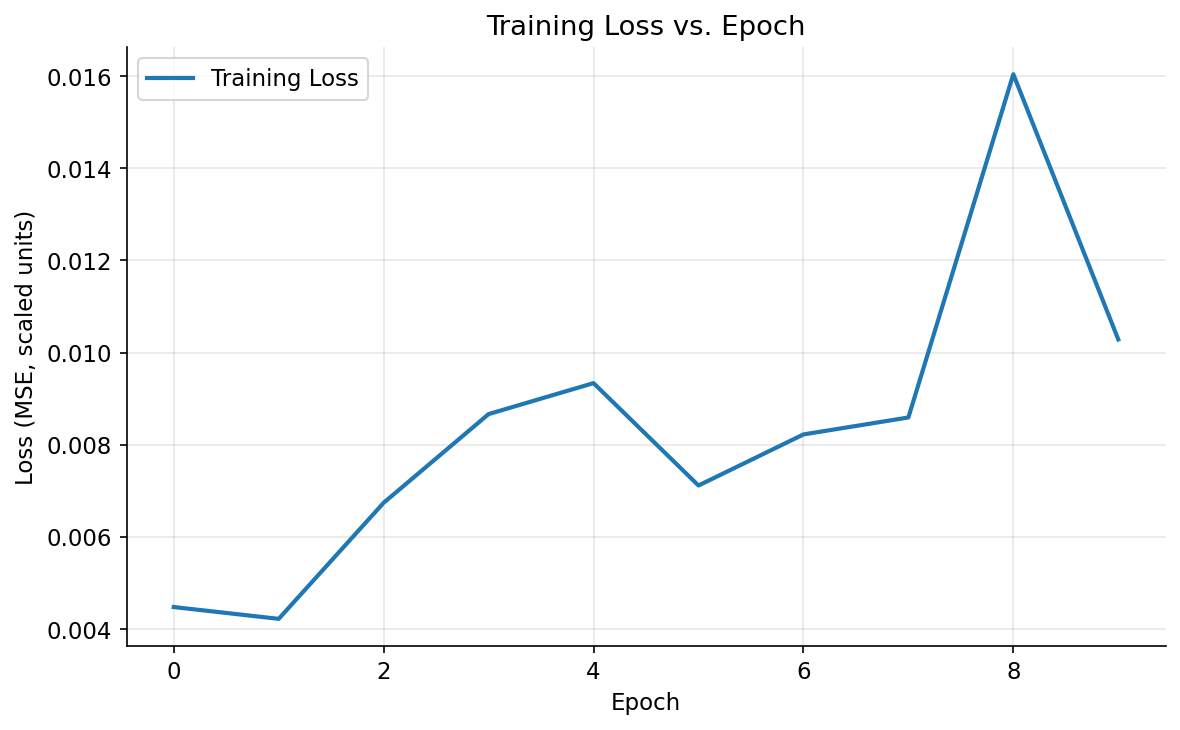

In [13]:
# --- Figure 1: Training Loss vs Epoch ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history.history['loss'], color='#1f77b4', linewidth=2, label='Training Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (MSE, scaled units)')
ax.set_title('Training Loss vs. Epoch')
ax.legend()
plt.tight_layout()
plt.savefig('training_loss_vs_epoch.png', dpi=300, bbox_inches='tight')
plt.show()


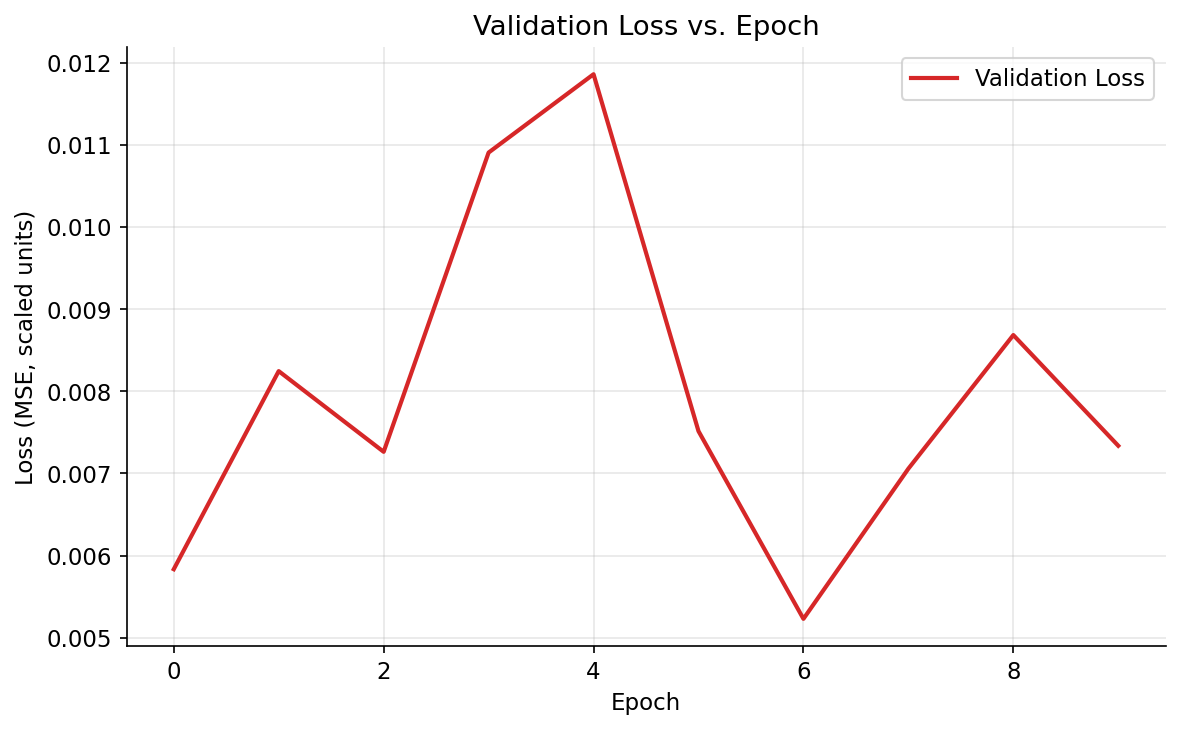

In [14]:
# --- Figure 2: Validation Loss vs Epoch ---
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history.history['val_loss'], color='#d62728', linewidth=2, label='Validation Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (MSE, scaled units)')
ax.set_title('Validation Loss vs. Epoch')
ax.legend()
plt.tight_layout()
plt.savefig('validation_loss_vs_epoch.png', dpi=300, bbox_inches='tight')
plt.show()


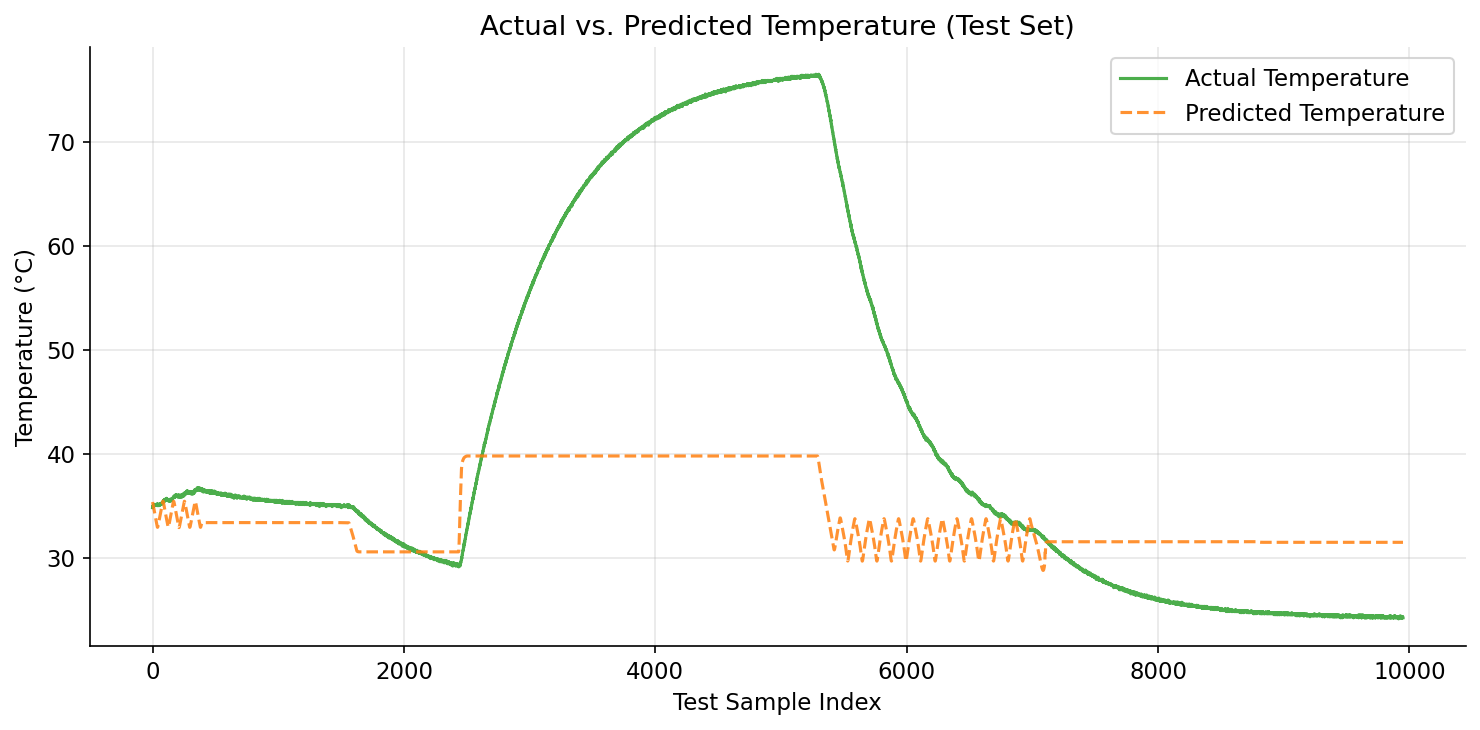

In [15]:
# --- Figure 3: Actual vs Predicted Temperature ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(y_true, color='#2ca02c', linewidth=1.5, label='Actual Temperature', alpha=0.85)
ax.plot(y_pred, color='#ff7f0e', linewidth=1.5, label='Predicted Temperature', alpha=0.85, linestyle='--')
ax.set_xlabel('Test Sample Index')
ax.set_ylabel('Temperature (°C)')
ax.set_title('Actual vs. Predicted Temperature (Test Set)')
ax.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted_temperature.png', dpi=300, bbox_inches='tight')
plt.show()


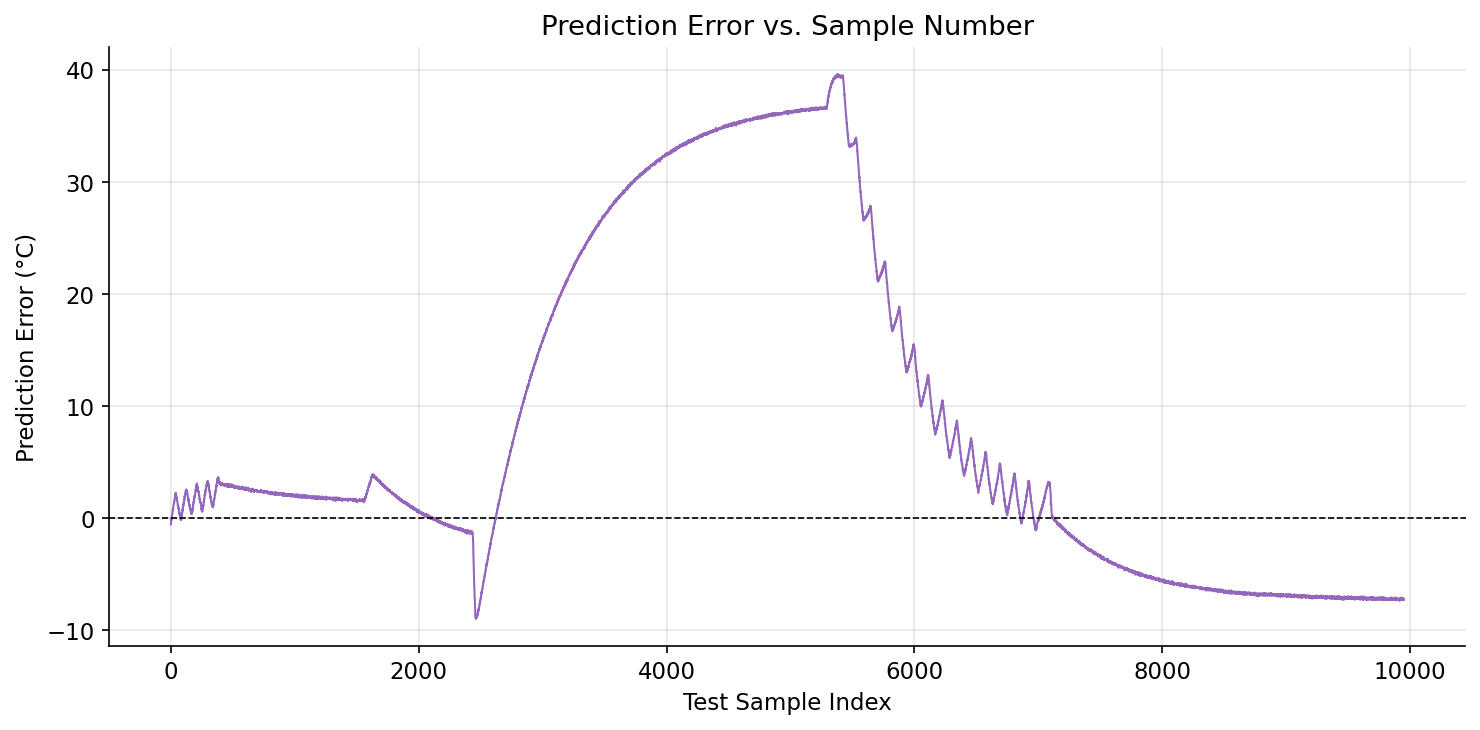

In [16]:
# --- Figure 4: Prediction Error vs Sample Number ---
prediction_error = (y_true - y_pred).flatten()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(prediction_error, color='#9467bd', linewidth=1.0)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Test Sample Index')
ax.set_ylabel('Prediction Error (°C)')
ax.set_title('Prediction Error vs. Sample Number')
plt.tight_layout()
plt.savefig('prediction_error_vs_sample.png', dpi=300, bbox_inches='tight')
plt.show()


## 11. Export Predictions

Saves a CSV file (`prediction_results.csv`) containing, for each test-set sample:
- `Time_s`
- `ActualTemperature`
- `PredictedTemperature`
- `PredictionError`


In [17]:
results_df = pd.DataFrame({
    'Time_s': test_time_targets,
    'ActualTemperature': y_true.flatten(),
    'PredictedTemperature': y_pred.flatten(),
    'PredictionError': prediction_error
})

results_df.to_csv('prediction_results.csv', index=False)
print("Predictions saved to: prediction_results.csv")
display(results_df.head(10))


Predictions saved to: prediction_results.csv


,Time_s,ActualTemperature,PredictedTemperature,PredictionError
0,40050.0,34.8,35.340237,-0.540237
1,40051.0,34.9,35.287201,-0.387201
2,40052.0,34.9,35.229305,-0.329305
3,40053.0,34.9,35.168732,-0.268732
4,40054.0,35.0,35.106884,-0.106884
5,40055.0,34.9,35.044582,-0.144582
6,40056.0,35.0,34.982174,0.017826
7,40057.0,34.9,34.919750,-0.019750
8,40058.0,35.0,34.857243,0.142757
9,40059.0,35.0,34.794525,0.205475


## Summary

- The LSTM predictor was trained to estimate component temperature from a 50-step history of
  `Current_A`, following the methodology of arXiv:2405.18321v1.
- The trained model is saved as `lstm_temperature_model.keras` and can be loaded directly with
  `keras.models.load_model('lstm_temperature_model.keras')` in a subsequent notebook.
- `prediction_results.csv` contains the per-sample test predictions and errors, which can serve
  as the basis for a downstream **anomaly detection** notebook (residual-based thresholding, etc.),
  which is **out of scope** for this notebook.
